In [22]:
from pathlib import Path
import os

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

os.chdir(project_root)

print("Current working directory:")
print(os.getcwd())

Current working directory:
/home/anshul/crop-disease-detection


In [23]:
import json
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import cv2

IMG_SIZE = (224, 224)

print("TensorFlow version:", tf.__version__)
print("OpenCV version:", cv2.__version__)

TensorFlow version: 2.21.0
OpenCV version: 5.1.0


In [24]:
model = keras.models.load_model("models/best_baseline_model.keras")

with open("models/class_names.json", "r") as f:
    class_names = json.load(f)

print("Model loaded successfully.")
print("Number of classes:", len(class_names))

Model loaded successfully.
Number of classes: 38


In [25]:
conv_layers = []

for layer in model.layers:
    if "conv" in layer.name.lower():
        conv_layers.append(layer.name)

print("Convolutional layers:")
print(conv_layers)

last_conv_layer_name = conv_layers[-1]

print("\nLast convolutional layer:")
print(last_conv_layer_name)

Convolutional layers:
['conv2d', 'conv2d_1', 'conv2d_2', 'conv2d_3']

Last convolutional layer:
conv2d_3


In [26]:
def build_grad_model(model, layer_name):
    inputs = keras.Input(shape=(224, 224, 3))
    x = inputs
    target = None
    for layer in model.layers:
        if isinstance(layer, keras.layers.InputLayer):
            continue
        x = layer(x)
        if layer.name == layer_name:
            target = x
    return keras.models.Model(inputs, [target, x])


def make_gradcam_heatmap(img_array, grad_model, pred_index=None):
    with tf.GradientTape() as tape:
        conv_output, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_output)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = tf.reduce_sum(conv_output[0] * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def overlay_heatmap(image_uint8, heatmap, alpha=0.5, threshold=0.2):
    hm = cv2.resize(heatmap, (image_uint8.shape[1], image_uint8.shape[0]),
                    interpolation=cv2.INTER_CUBIC)
    hm = np.clip(hm, 0, 1)
    hm[hm < threshold] = 0
    hm_color = cv2.applyColorMap(np.uint8(255 * hm), cv2.COLORMAP_JET)
    hm_color = cv2.cvtColor(hm_color, cv2.COLOR_BGR2RGB)
    mask = (hm > 0)[..., None]
    blended = cv2.addWeighted(image_uint8, 1 - alpha, hm_color, alpha, 0)
    return np.where(mask, blended, image_uint8)

['conv2d', 'conv2d_1', 'conv2d_2', 'conv2d_3']


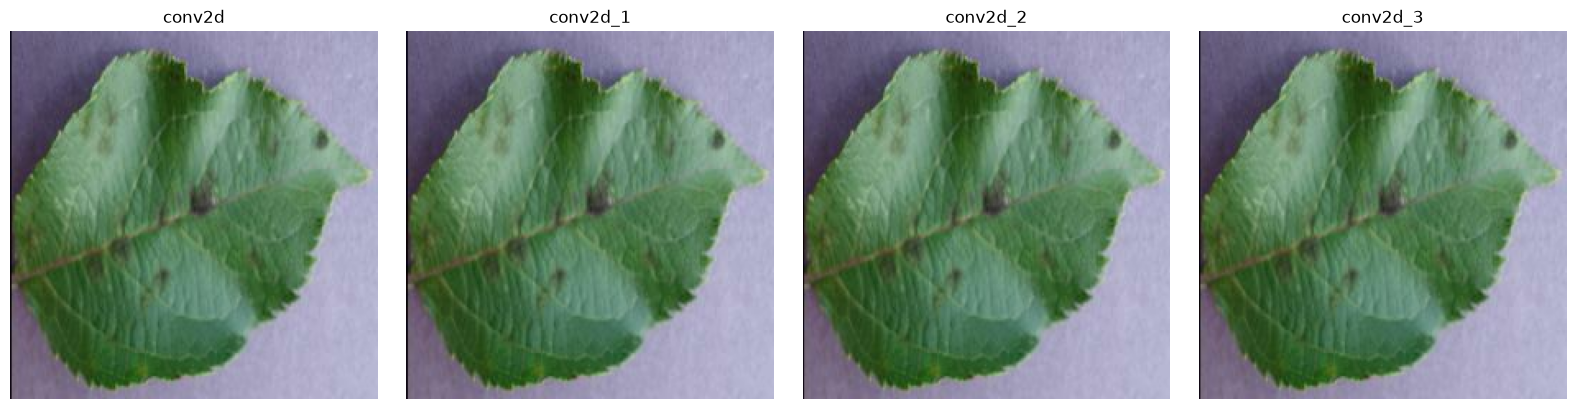

In [27]:
conv_layers = [l.name for l in model.layers if isinstance(l, keras.layers.Conv2D)]
print(conv_layers)

sample_img = tf.expand_dims(test_image, 0)
img_u8 = np.uint8(test_image.numpy() * 255)

plt.figure(figsize=(4 * len(conv_layers), 4))
for i, name in enumerate(conv_layers):
    gm = build_grad_model(model, name)
    hm = make_gradcam_heatmap(sample_img, gm)
    plt.subplot(1, len(conv_layers), i + 1)
    plt.imshow(overlay_heatmap(img_u8, hm))
    plt.title(name)
    plt.axis("off")
plt.tight_layout()
plt.show()

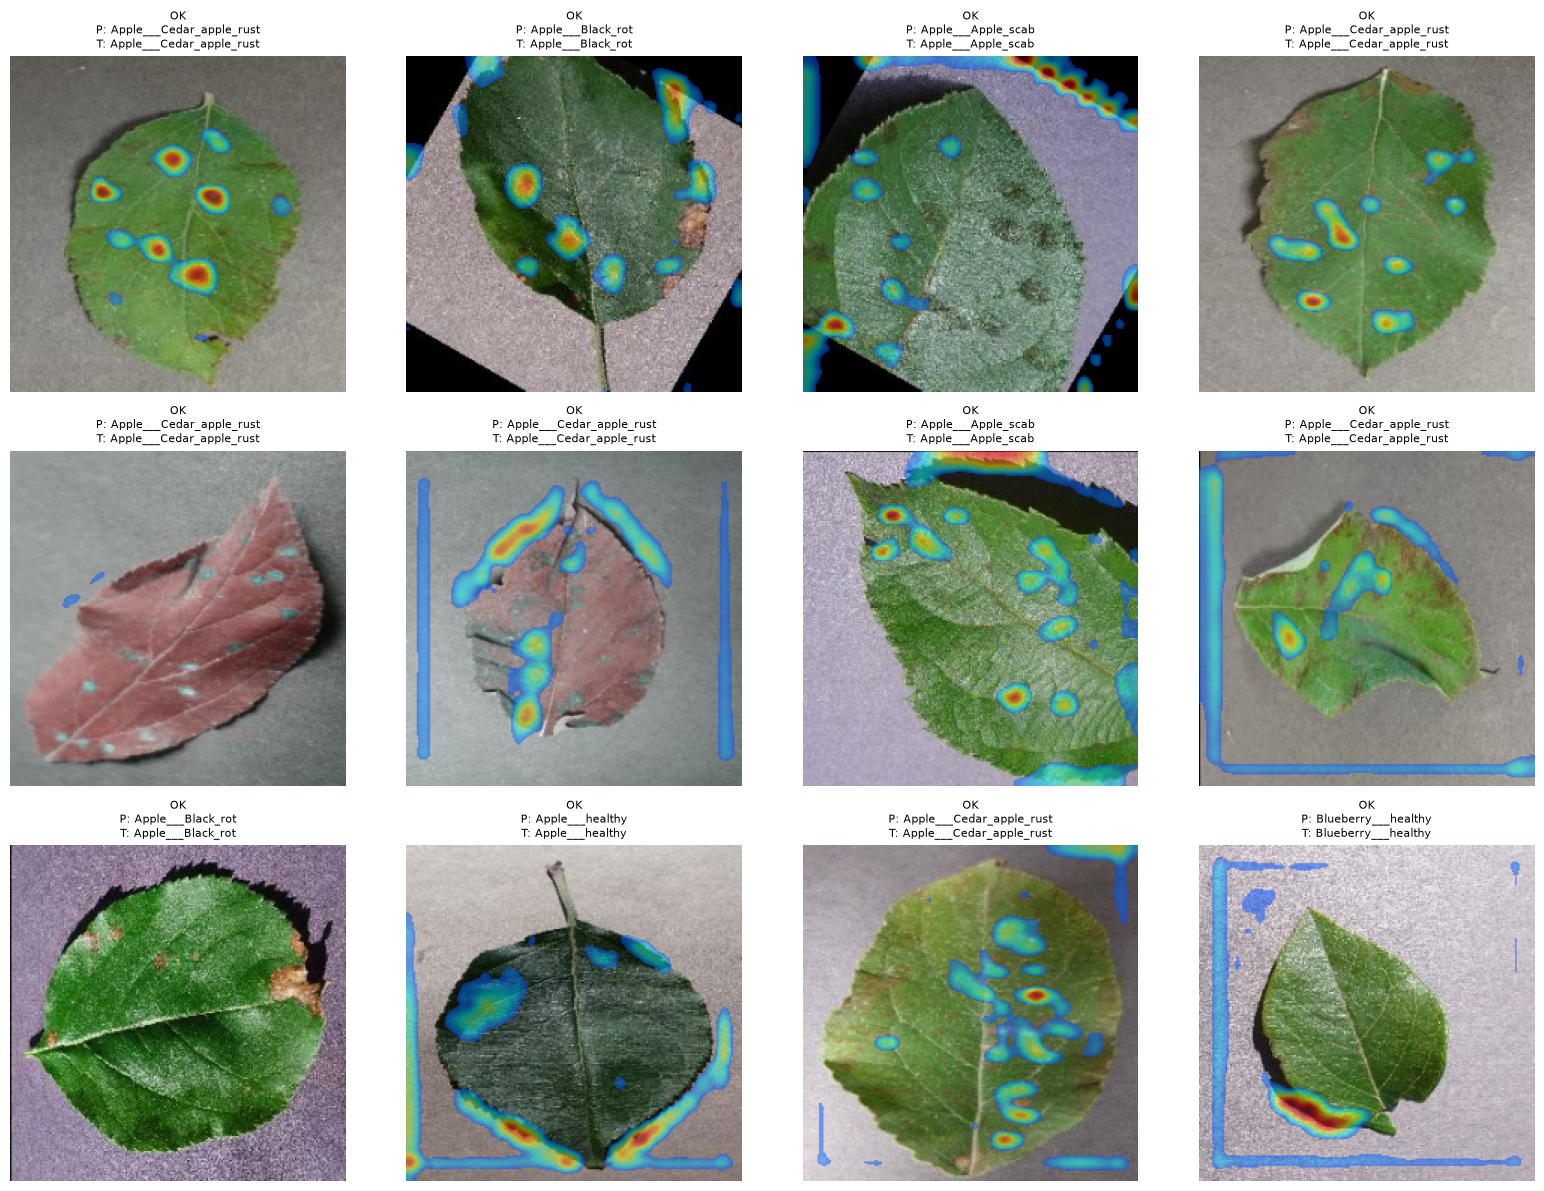

In [28]:
import random
os.makedirs("results/gradcam", exist_ok=True)

grad_model = build_grad_model(model, last_conv_layer_name)

samples = list(valid_data.unbatch().shuffle(2000, seed=42).take(12))

plt.figure(figsize=(16, 12))
for i, (img, label) in enumerate(samples):
    arr = tf.expand_dims(img, 0)
    pred = model.predict(arr, verbose=0)
    pc = int(np.argmax(pred[0]))
    hm = make_gradcam_heatmap(arr, grad_model, pc)
    u8 = np.uint8(img.numpy() * 255)

    plt.subplot(3, 4, i + 1)
    plt.imshow(overlay_heatmap(u8, hm))
    ok = "OK" if pc == int(label) else "WRONG"
    plt.title(f"{ok}\nP: {class_names[pc][:28]}\nT: {class_names[int(label)][:28]}", fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.savefig("results/gradcam/baseline_gradcam_grid.png", dpi=200)
plt.show()

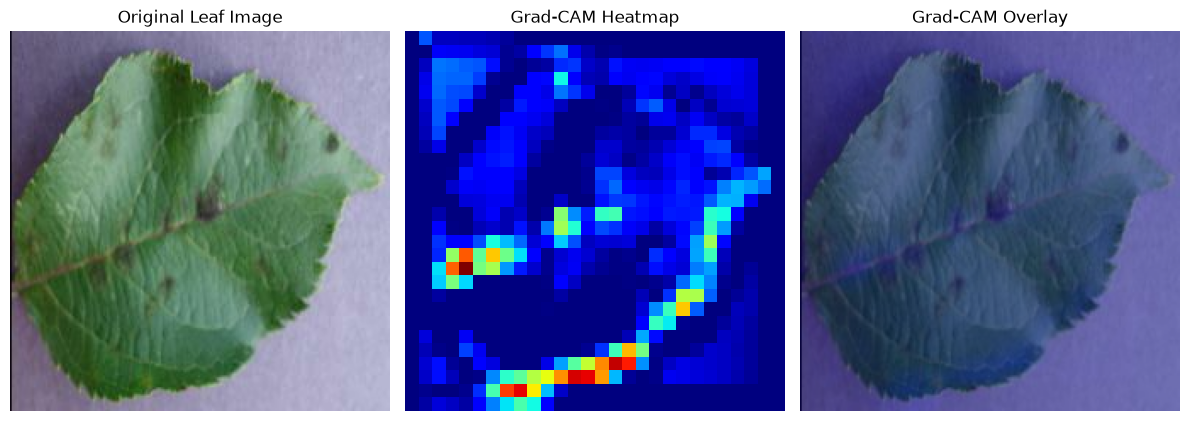

In [29]:
original_image = test_image.numpy()
original_image = np.uint8(original_image * 255)

heatmap_resized = cv2.resize(heatmap, (original_image.shape[1], original_image.shape[0]))
heatmap_colored = cm.jet(heatmap_resized)[..., :3]
heatmap_colored = np.uint8(heatmap_colored * 255)

superimposed_image = cv2.addWeighted(
    original_image,
    0.6,
    heatmap_colored,
    0.4,
    0
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Leaf Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(superimposed_image)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [30]:
def leaf_mask(img_u8):
    hsv = cv2.cvtColor(img_u8, cv2.COLOR_RGB2HSV)
    h, s, v = cv2.split(hsv)
    mask = ((h > 10) & (h < 90) & (s > 40)).astype(np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
    return mask

def off_leaf_ratio(img_u8, heatmap):
    hm = cv2.resize(heatmap, (224, 224), interpolation=cv2.INTER_CUBIC)
    hm = np.clip(hm, 0, 1)
    m = leaf_mask(img_u8)
    return float(hm[m == 0].sum() / (hm.sum() + 1e-8))

ratios = []
for img, label in valid_data.unbatch().shuffle(2000, seed=1).take(300):
    arr = tf.expand_dims(img, 0)
    hm = make_gradcam_heatmap(arr, grad_model)
    ratios.append(off_leaf_ratio(np.uint8(img.numpy() * 255), hm))

print("Mean off-leaf ratio:", np.mean(ratios))
print("Share of images with ratio > 0.5:", np.mean(np.array(ratios) > 0.5))

Mean off-leaf ratio: 0.4868593280762434
Share of images with ratio > 0.5: 0.43333333333333335


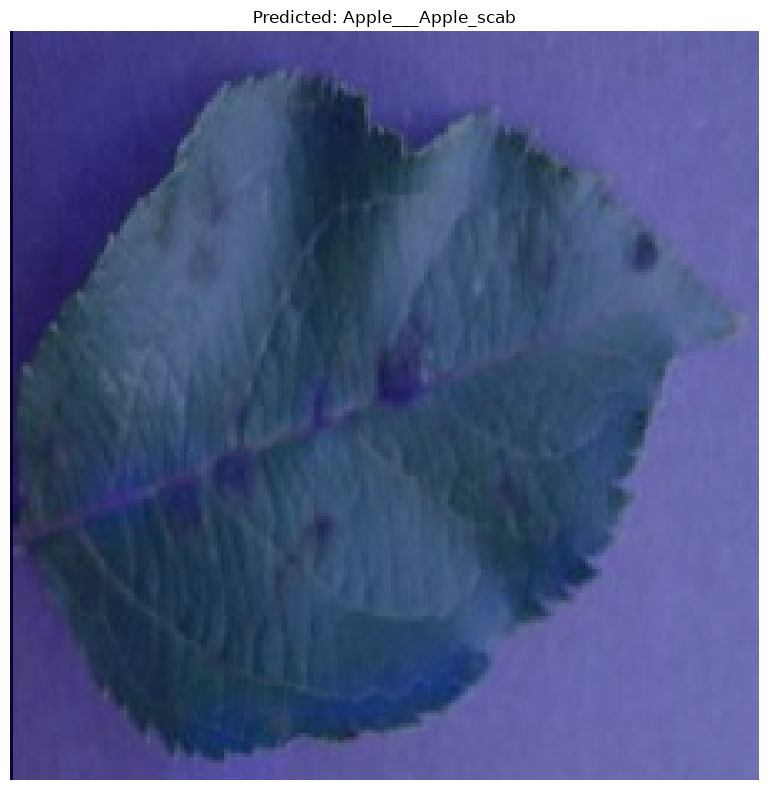

Grad-CAM image saved to results/gradcam/baseline_gradcam_example.png


In [31]:
os.makedirs("results/gradcam", exist_ok=True)

plt.figure(figsize=(8, 8))
plt.imshow(superimposed_image)
plt.title(f"Predicted: {class_names[predicted_class]}")
plt.axis("off")
plt.tight_layout()
plt.savefig("results/gradcam/baseline_gradcam_example.png", dpi=300)
plt.show()

print("Grad-CAM image saved to results/gradcam/baseline_gradcam_example.png")